In [56]:
import oracledb
from getpass import getpass

password = getpass("Пароль: ")

connection = oracledb.connect(
    user="fraud_user",
    password=password,
    dsn="localhost:1522/FREEPDB1"
)

print(connection.version)

23.26.3.0.0


In [57]:
with connection.cursor() as cursor:
    cursor.execute("""
        SELECT COUNT(*)
        FROM transactions_risk
    """)

    rows_count = cursor.fetchone()[0]

print(rows_count)

2770409


In [58]:
import pandas as pd

from sqlalchemy import URL, create_engine

db_url = URL.create(
    drivername="oracle+oracledb",
    username="fraud_user",
    password=password,
    host="localhost",
    port=1522,
    query={"service_name": "FREEPDB1"},)

engine = create_engine(db_url)

In [59]:
query = """
SELECT
    step,
    transaction_type,
    amount,
    old_balance_orig,
    new_balance_orig,
    old_balance_dest,
    new_balance_dest,
    is_fraud,
    name_orig,
    name_dest,
    is_flagged_fraud
FROM transactions_risk
"""

data_chunks = []

for chunk in pd.read_sql_query(
    query,
    con=engine,
    chunksize=200_000
):
    chunk.columns = chunk.columns.str.lower()

    chunk = chunk.astype({
        "step": "int16",
        "transaction_type": "category",
        "amount": "float64",
        "old_balance_orig": "float64",
        "new_balance_orig": "float64",
        "old_balance_dest": "float64",
        "new_balance_dest": "float64",
        "is_fraud": "int8",
        "name_orig": "string",
        "name_dest": "string",
        "is_flagged_fraud": "int8"
    })

    data_chunks.append(chunk)

risk_df = pd.concat(data_chunks, ignore_index=True)

del data_chunks

In [60]:
risk_df.head()
risk_df.shape
risk_df.dtypes
risk_df.isna().sum()
risk_df["is_fraud"].value_counts()

is_fraud
0    2762196
1       8213
Name: count, dtype: int64

In [61]:
risk_df.head()

,step,transaction_type,amount,old_balance_orig,new_balance_orig,old_balance_dest,new_balance_dest,is_fraud,name_orig,name_dest,is_flagged_fraud
0,1,TRANSFER,181.00,181.0,0.0,0.0,0.00,1,C1305486145,C553264065,0
1,1,CASH_OUT,181.00,181.0,0.0,21182.0,0.00,1,C840083671,C38997010,0
2,1,CASH_OUT,229133.94,15325.0,0.0,5083.0,51513.44,0,C905080434,C476402209,0
3,1,TRANSFER,215310.30,705.0,0.0,22425.0,0.00,0,C1670993182,C1100439041,0
4,1,TRANSFER,311685.89,10835.0,0.0,6267.0,2719172.89,0,C1984094095,C932583850,0


In [62]:
import numpy as np

model_df = risk_df[
    ["step", 
     "transaction_type", 
     "amount", "old_balance_orig", 
     "new_balance_orig", 
     "old_balance_dest", 
     "new_balance_dest",
     "name_orig",
     "name_dest", 
     "is_fraud"]
    ].copy()

In [63]:
model_df["hour"] = (
    (model_df["step"] - 1) % 24
).astype("int8")

model_df["day"] = (
    (model_df["step"] - 1) // 24 + 1
).astype("int16")

model_df["log_amount"] = np.log1p(
    model_df["amount"]
).astype("float32")

In [64]:
model_df[
    ["step", "hour", "day", "amount", "log_amount"]
].head(10)

,step,hour,day,amount,log_amount
0,1,0,1,181.00,5.204007
1,1,0,1,181.00,5.204007
2,1,0,1,229133.94,12.342067
3,1,0,1,215310.30,12.279840
4,1,0,1,311685.89,12.649755
5,1,0,1,110414.71,11.612008
6,1,0,1,56953.90,10.950015
7,1,0,1,5346.89,8.584457
8,1,0,1,23261.30,10.054589
9,1,0,1,62610.80,11.044709


In [65]:
model_df[
    ["step", "hour", "day", "amount", "log_amount"]
].describe()

,step,hour,day,amount,log_amount
count,2.770409e+06,2.770409e+06,2.770409e+06,2.770409e+06,2.770409e+06
mean,2.420081e+02,1.446657e+01,1.043923e+01,3.175361e+05,1.192780e+01
std,1.416191e+02,3.868813e+00,5.893272e+00,8.877897e+05,1.232817e+00
min,1.000000e+00,0.000000e+00,1.000000e+00,0.000000e+00,0.000000e+00
25%,1.550000e+02,1.100000e+01,7.000000e+00,8.297354e+04,1.132629e+01
50%,2.360000e+02,1.500000e+01,1.000000e+01,1.712609e+05,1.205095e+01
75%,3.320000e+02,1.800000e+01,1.400000e+01,3.067912e+05,1.263393e+01
max,7.430000e+02,2.300000e+01,3.100000e+01,9.244552e+07,1.834213e+01


In [66]:
origin_has_balance = model_df["old_balance_orig"] > 0

model_df["origin_zero_balance"] = (
    model_df["old_balance_orig"] == 0
).astype("int8")

model_df["destination_zero_balance"] = (
    model_df["old_balance_dest"] == 0
).astype("int8")

In [67]:
ratio = np.zeros(len(model_df), dtype="float64")

np.divide(
    model_df["amount"].to_numpy(),
    model_df["old_balance_orig"].to_numpy(),
    out=ratio,
    where=origin_has_balance.to_numpy()
)

model_df["amount_to_balance_ratio"] = ratio.astype("float32")

model_df["log_amount_to_balance_ratio"] = np.log1p(
    ratio
).astype("float32")

In [68]:
model_df["full_balance_attempt"] = (
    origin_has_balance
    & np.isclose(
        model_df["amount"],
        model_df["old_balance_orig"],
        rtol=0,
        atol=0.01
    )
).astype("int8")

In [69]:
model_df["log_old_balance_orig"] = np.log1p(
    model_df["old_balance_orig"]
).astype("float32")

model_df["log_old_balance_dest"] = np.log1p(
    model_df["old_balance_dest"]
).astype("float32")

In [70]:
model_df[
    [
        "amount",
        "old_balance_orig",
        "amount_to_balance_ratio",
        "log_amount_to_balance_ratio",
        "origin_zero_balance",
        "destination_zero_balance",
        "full_balance_attempt"
    ]
].head(10)

,amount,old_balance_orig,amount_to_balance_ratio,log_amount_to_balance_ratio,origin_zero_balance,destination_zero_balance,full_balance_attempt
0,181.00,181.00,1.000000,0.693147,0,1,1
1,181.00,181.00,1.000000,0.693147,0,0,1
2,229133.94,15325.00,14.951644,2.769562,0,0,0
3,215310.30,705.00,305.404694,5.724907,0,0,0
4,311685.89,10835.00,28.766579,3.393386,0,0,0
5,110414.71,26845.41,4.112983,1.631783,0,0,0
6,56953.90,1942.02,29.327145,3.412043,0,0,0
7,5346.89,0.00,0.000000,0.000000,1,0,0
8,23261.30,20411.53,1.139616,0.760626,0,0,0
9,62610.80,79114.00,0.791400,0.582997,0,0,0


In [71]:
binary_comparison = (
    model_df
    .groupby("is_fraud")[
        [
            "origin_zero_balance",
            "destination_zero_balance",
            "full_balance_attempt"
        ]
    ]
    .mean()
    .mul(100)
    .round(2)
)

binary_comparison

,origin_zero_balance,destination_zero_balance,full_balance_attempt
is_fraud,,,
0,47.37,13.90,0.00
1,0.50,65.15,97.63


In [72]:
model_df.groupby("is_fraud")["full_balance_attempt"].agg(
    transactions_count="count",
    full_balance_attempt_count="sum",
    full_balance_attempt_rate="mean"
)

,transactions_count,full_balance_attempt_count,full_balance_attempt_rate
is_fraud,,,
0,2762196,0,0.000000
1,8213,8018,0.976257


In [73]:
model_df["hour_sin"] = np.sin(
    2 * np.pi * model_df["hour"] / 24
).astype("float32")

model_df["hour_cos"] = np.cos(
    2 * np.pi * model_df["hour"] / 24
).astype("float32")

In [74]:
model_df[
    ["hour", "hour_sin", "hour_cos"]
].drop_duplicates().sort_values("hour")

,hour,hour_sin,hour_cos
0,0,0.000000e+00,1.000000e+00
664,1,2.588190e-01,9.659258e-01
849,2,5.000000e-01,8.660254e-01
936,3,7.071068e-01,7.071068e-01
1055,4,8.660254e-01,5.000000e-01
1146,5,9.659258e-01,2.588190e-01
1482,6,1.000000e+00,6.123234e-17
3389,7,9.659258e-01,-2.588190e-01
11503,8,8.660254e-01,-5.000000e-01
27710,9,7.071068e-01,-7.071068e-01


In [75]:
model_df.columns

Index(['step', 'transaction_type', 'amount', 'old_balance_orig',
       'new_balance_orig', 'old_balance_dest', 'new_balance_dest', 'name_orig',
       'name_dest', 'is_fraud', 'hour', 'day', 'log_amount',
       'origin_zero_balance', 'destination_zero_balance',
       'amount_to_balance_ratio', 'log_amount_to_balance_ratio',
       'full_balance_attempt', 'log_old_balance_orig', 'log_old_balance_dest',
       'hour_sin', 'hour_cos'],
      dtype='str')

In [76]:
model_df.head(1).T

,0
step,1
transaction_type,TRANSFER
amount,181.0
old_balance_orig,181.0
new_balance_orig,0.0
old_balance_dest,0.0
new_balance_dest,0.0
name_orig,C1305486145
name_dest,C553264065
is_fraud,1


In [77]:
continuous_features = [
    "day",
    "log_amount",
    "log_old_balance_orig",
    "log_old_balance_dest",
    "log_amount_to_balance_ratio",
    "hour_sin",
    "hour_cos"
]

binary_features = [
    "origin_zero_balance",
    "destination_zero_balance",
    "full_balance_attempt"
]

categorical_features = [
    "transaction_type"
]

feature_columns = (
    continuous_features
    + binary_features
    + categorical_features
)

feature_columns

['day',
 'log_amount',
 'log_old_balance_orig',
 'log_old_balance_dest',
 'log_amount_to_balance_ratio',
 'hour_sin',
 'hour_cos',
 'origin_zero_balance',
 'destination_zero_balance',
 'full_balance_attempt',
 'transaction_type']

In [78]:
X = model_df[feature_columns].copy()
y = model_df["is_fraud"].copy()
print(X.shape, y.shape)

(2770409, 11) (2770409,)


In [79]:
max_step = model_df["step"].max()
train_step = int(model_df["step"].quantile(0.70))
validation_step = int(model_df["step"].quantile(0.85))

train_mask = model_df["step"] <= train_step

validation_mask = (
    (model_df["step"] > train_step)
    & (model_df["step"] <= validation_step)
)

test_mask = model_df["step"] > validation_step

print("Последний step:", max_step)
print("Конец train:", train_step)
print("Конец validation:", validation_step)

print("Train:", train_mask.sum())
print("Validation:", validation_mask.sum())
print("Test:", test_mask.sum())

Последний step: 743
Конец train: 323
Конец validation: 377
Train: 1951895
Validation: 410437
Test: 408077


In [80]:
print("Train fraud:", y.loc[train_mask].sum())
print("Validation fraud:", y.loc[validation_mask].sum())
print("Test fraud:", y.loc[test_mask].sum())

Train fraud: 3643
Validation fraud: 560
Test fraud: 4010


As we can see, the training, validation, test are splitted by step, because its the only measure that shows us periodical data. But, there was a problem that step could be have high concentration of operations in particular area and it was neccessary to work with quantile for splitting the data by correct proportion of 70 15 15. Also, it was important to have is_fraud = 1 attribute in every splitted Hold-out aspect and we clarified that testing part has high fraud proportion is 4030. Data drift was highlighted 

In [81]:
X_train = X.loc[train_mask].copy()
y_train = y.loc[train_mask].copy()

X_validation = X.loc[validation_mask].copy()
y_validation = y.loc[validation_mask].copy()

X_test = X.loc[test_mask].copy()
y_test = y.loc[test_mask].copy()

print(X_train.shape, y_train.shape)
print(X_validation.shape, y_validation.shape)
print(X_test.shape, y_test.shape)

(1951895, 11) (1951895,)
(410437, 11) (410437,)
(408077, 11) (408077,)


We decided to take amount for our analysis for business side

In [82]:
amount_validation = model_df.loc[
    validation_mask, "amount"
].copy()

amount_test = model_df.loc[
    test_mask, "amount"
].copy()

print(amount_validation.shape)
print(amount_test.shape)

(410437,)
(408077,)


In [83]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

preprocessor = ColumnTransformer(
    transformers=[
        (
            "continuous",
            StandardScaler(),
            continuous_features
        ),
        (
            "binary",
            "passthrough",
            binary_features
        ),
        (
            "categorical",
            OneHotEncoder(
                drop="if_binary",
                handle_unknown="ignore"
            ),
            categorical_features
        )
    ],
    remainder="drop"
)

preprocessor

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('continuous', ...), ('binary', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and `

In [84]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

logistic_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            LogisticRegression(
                class_weight="balanced",
                max_iter=1000,
                random_state=42
            )
        )
    ]
)

logistic_model

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('continuous', ...), ('binary', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: floa

In [85]:
import time

start_time = time.time()

logistic_model.fit(X_train, y_train)

training_time = time.time() - start_time

print(f"Обучение завершено за {training_time:.1f} секунд")

Обучение завершено за 16.6 секунд


In [86]:
validation_probabilities = logistic_model.predict_proba(
    X_validation
)[:, 1]

In [87]:
print("Количество прогнозов:", validation_probabilities.shape)
print("Минимальная вероятность:", validation_probabilities.min())
print("Максимальная вероятность:", validation_probabilities.max())
print("Первые 10 вероятностей:")
print(validation_probabilities[:10])

Количество прогнозов: (410437,)
Минимальная вероятность: 2.0556675085394822e-10
Максимальная вероятность: 1.0
Первые 10 вероятностей:
[1.83604983e-03 1.94805359e-04 3.57186177e-06 5.92317743e-04
 8.64527592e-06 5.31265985e-04 2.59634487e-03 1.06877982e-05
 1.21539867e-05 6.66778036e-05]


In [88]:
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    average_precision_score,
    roc_auc_score
)

default_threshold = 0.5

validation_predictions = (
    validation_probabilities >= default_threshold
).astype(int)

print("Предсказано мошеннических операций:",
      validation_predictions.sum())

print("\nConfusion matrix:")
print(confusion_matrix(y_validation, validation_predictions))

print("\nClassification report:")
print(
    classification_report(
        y_validation,
        validation_predictions,
        digits=4,
        zero_division=0
    )
)

print(
    "PR-AUC:",
    round(
        average_precision_score(
            y_validation,
            validation_probabilities
        ),
        4
    )
)

print(
    "ROC-AUC:",
    round(
        roc_auc_score(
            y_validation,
            validation_probabilities
        ),
        4
    )
)

Предсказано мошеннических операций: 560

Confusion matrix:
[[409877      0]
 [     0    560]]

Classification report:
              precision    recall  f1-score   support

           0     1.0000    1.0000    1.0000    409877
           1     1.0000    1.0000    1.0000       560

    accuracy                         1.0000    410437
   macro avg     1.0000    1.0000    1.0000    410437
weighted avg     1.0000    1.0000    1.0000    410437

PR-AUC: 1.0
ROC-AUC: 1.0


There we can see that model is working ideal and the reason can be that feature(full_balance_amount) is valuable, showing the  100 percent correctness. Thats why we need to remove it.

In [89]:
binary_features_prod = [
    "origin_zero_balance",
    "destination_zero_balance"
]

feature_columns_prod = (
    continuous_features
    + binary_features_prod
    + categorical_features
)

X_train_prod = X_train[feature_columns_prod].copy()
X_validation_prod = X_validation[feature_columns_prod].copy()
X_test_prod = X_test[feature_columns_prod].copy()

print(X_train_prod.columns.tolist())
print(X_train_prod.shape)

['day', 'log_amount', 'log_old_balance_orig', 'log_old_balance_dest', 'log_amount_to_balance_ratio', 'hour_sin', 'hour_cos', 'origin_zero_balance', 'destination_zero_balance', 'transaction_type']
(1951895, 10)


In [90]:
preprocessor_prod = ColumnTransformer(
    transformers=[
        (
            "continuous",
            StandardScaler(),
            continuous_features
        ),
        (
            "binary",
            "passthrough",
            binary_features_prod
        ),
        (
            "categorical",
            OneHotEncoder(
                drop="if_binary",
                handle_unknown="ignore"
            ),
            categorical_features
        )
    ],
    remainder="drop"
)

In [91]:
logistic_model_prod = Pipeline(
    steps=[
        ("preprocessor", preprocessor_prod),
        (
            "classifier",
            LogisticRegression(
                class_weight="balanced",
                max_iter=1000,
                random_state=42
            )
        )
    ]
)

logistic_model_prod.fit(X_train_prod, y_train)

validation_probabilities_prod = (
    logistic_model_prod.predict_proba(X_validation_prod)[:, 1]
)

print(validation_probabilities_prod[:10])

[3.67632989e-09 9.63466291e-02 1.01269599e-02 8.41609334e-05
 8.10622078e-05 5.95572037e-04 1.37167487e-02 8.12665735e-03
 3.47521352e-02 3.91259037e-05]


In [92]:
from sklearn.metrics import (
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
    roc_auc_score
)

threshold = 0.5

validation_predictions_prod = (
    validation_probabilities_prod >= threshold
).astype(int)

tn, fp, fn, tp = confusion_matrix(
    y_validation,
    validation_predictions_prod
).ravel()

print("Правильно пропущенные обычные операции:", tn)
print("Ложные тревоги:", fp)
print("Пропущенные мошенничества:", fn)
print("Обнаруженные мошенничества:", tp)

print("\nPrecision:",
      round(precision_score(y_validation, validation_predictions_prod), 4))

print("Recall:",
      round(recall_score(y_validation, validation_predictions_prod), 4))

print("F1-score:",
      round(f1_score(y_validation, validation_predictions_prod), 4))

print("PR-AUC:",
      round(average_precision_score(
          y_validation,
          validation_probabilities_prod
      ), 4))

print("ROC-AUC:",
      round(roc_auc_score(
          y_validation,
          validation_probabilities_prod
      ), 4))

Правильно пропущенные обычные операции: 382753
Ложные тревоги: 27124
Пропущенные мошенничества: 62
Обнаруженные мошенничества: 498

Precision: 0.018
Recall: 0.8893
F1-score: 0.0353
PR-AUC: 0.3838
ROC-AUC: 0.9803


In [93]:
thresholds = [
    0.50,
    0.70,
    0.80,
    0.90,
    0.95,
    0.97,
    0.99,
    0.995,
    0.999
]

threshold_results = []

for threshold in thresholds:
    predictions = (
        validation_probabilities_prod >= threshold
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_validation,
        predictions
    ).ravel()

    threshold_results.append({
        "threshold": threshold,
        "alerts": tp + fp,
        "true_fraud": tp,
        "false_alerts": fp,
        "missed_fraud": fn,
        "precision": precision_score(
            y_validation,
            predictions,
            zero_division=0
        ),
        "recall": recall_score(
            y_validation,
            predictions
        ),
        "f1": f1_score(
            y_validation,
            predictions,
            zero_division=0
        )
    })

threshold_results_df = pd.DataFrame(threshold_results)

threshold_results_df.round(4)

,threshold,alerts,true_fraud,false_alerts,missed_fraud,precision,recall,f1
0,0.500,27622,498,27124,62,0.0180,0.8893,0.0353
1,0.700,11764,449,11315,111,0.0382,0.8018,0.0729
2,0.800,5709,396,5313,164,0.0694,0.7071,0.1263
3,0.900,1521,288,1233,272,0.1893,0.5143,0.2768
4,0.950,448,217,231,343,0.4844,0.3875,0.4306
5,0.970,230,158,72,402,0.6870,0.2821,0.4000
6,0.990,68,65,3,495,0.9559,0.1161,0.2070
7,0.995,23,23,0,537,1.0000,0.0411,0.0789
8,0.999,0,0,0,560,0.0000,0.0000,0.0000


In [94]:
selected_threshold = 0.70

validation_predictions_final = (
    validation_probabilities_prod >= selected_threshold
).astype(int)

print("Выбранный порог:", selected_threshold)
print("Количество тревог:", validation_predictions_final.sum())

Выбранный порог: 0.7
Количество тревог: 11764


By the analysing the approparate threshold we took the 0.7 and its depends on the business purposes. Now its crucal for us to determine the influence of features on logistic regression

In [95]:
fitted_preprocessor = (
    logistic_model_prod.named_steps["preprocessor"]
)

fitted_classifier = (
    logistic_model_prod.named_steps["classifier"]
)

feature_names = (
    fitted_preprocessor.get_feature_names_out()
)

coefficients = fitted_classifier.coef_[0]

coefficients_df = pd.DataFrame({
    "feature": feature_names,
    "coefficient": coefficients
})

coefficients_df["absolute_coefficient"] = (
    coefficients_df["coefficient"].abs()
)

coefficients_df = coefficients_df.sort_values(
    "absolute_coefficient",
    ascending=False
)

coefficients_df.round(4)

,feature,coefficient,absolute_coefficient
7,binary__origin_zero_balance,-27.5140,27.5140
4,continuous__log_amount_to_balance_ratio,-10.1092,10.1092
2,continuous__log_old_balance_orig,-7.2407,7.2407
1,continuous__log_amount,2.2173,2.2173
8,binary__destination_zero_balance,-0.9237,0.9237
3,continuous__log_old_balance_dest,-0.8809,0.8809
9,categorical__transaction_type_TRANSFER,0.8329,0.8329
5,continuous__hour_sin,0.6549,0.6549
6,continuous__hour_cos,0.6103,0.6103
0,continuous__day,-0.2671,0.2671


So, its time to check the model in test 

In [96]:
test_probabilities_prod = (
    logistic_model_prod.predict_proba(X_test_prod)[:, 1]
)

test_predictions_prod = (
    test_probabilities_prod >= selected_threshold
).astype(int)

tn, fp, fn, tp = confusion_matrix(
    y_test,
    test_predictions_prod
).ravel()

print("Правильно пропущенные обычные:", tn)
print("Ложные тревоги:", fp)
print("Пропущенные мошенничества:", fn)
print("Обнаруженные мошенничества:", tp)

print("\nPrecision:",
      round(precision_score(y_test, test_predictions_prod), 4))

print("Recall:",
      round(recall_score(y_test, test_predictions_prod), 4))

print("F1-score:",
      round(f1_score(y_test, test_predictions_prod), 4))

print("PR-AUC:",
      round(average_precision_score(
          y_test,
          test_probabilities_prod
      ), 4))

print("ROC-AUC:",
      round(roc_auc_score(
          y_test,
          test_probabilities_prod
      ), 4))

Правильно пропущенные обычные: 393935
Ложные тревоги: 10132
Пропущенные мошенничества: 1044
Обнаруженные мошенничества: 2966

Precision: 0.2264
Recall: 0.7397
F1-score: 0.3467
PR-AUC: 0.5621
ROC-AUC: 0.9724


In [97]:
def evaluate(model, X_part, y_part, threshold):
    proba = model.predict_proba(X_part)[:, 1]
    pred = (proba >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_part, pred).ravel()
    return {
        "TP": tp, "FN": fn, "FP": fp, "TN": tn,
        "precision": precision_score(y_part, pred, zero_division=0),
        "recall": recall_score(y_part, pred),
        "f1": f1_score(y_part, pred),
        "pr_auc": average_precision_score(y_part, proba),
        "roc_auc": roc_auc_score(y_part, proba),
    }

def make_logreg(continuous, binary, categorical):
    pre = ColumnTransformer(
        transformers=[
            ("continuous", StandardScaler(), continuous),
            ("binary", "passthrough", binary),
            ("categorical",
             OneHotEncoder(drop="if_binary", handle_unknown="ignore"),
             categorical),
        ],
        remainder="drop",
    )
    return Pipeline(steps=[
        ("preprocessor", pre),
        ("classifier", LogisticRegression(
            class_weight="balanced", max_iter=1000, random_state=42
        )),
    ])

thresholds = np.concatenate([np.arange(0.50, 0.99, 0.01), [0.99, 0.995, 0.999]])

def pick_threshold(model, X_val, y_val, min_recall=0.80):
    proba = model.predict_proba(X_val)[:, 1]
    best = None
    for t in thresholds:
        pred = (proba >= t).astype(int)
        rec = recall_score(y_val, pred)
        if rec >= min_recall:
            prec = precision_score(y_val, pred, zero_division=0)
            if best is None or prec > best[1]:
                best = (t, prec, rec)
    if best is None:
        # recall 80% недостижим: берём порог 0.5 и предупреждаем
        print("Внимание: recall 80% на validation не достигается, беру порог 0.5")
        return 0.5
    return best[0]

experiments = {
    "с day": continuous_features,
    "без day": [c for c in continuous_features if c != "day"],
}

models = {}
rows = []

for name, cont in experiments.items():
    cols = cont + binary_features_prod + categorical_features

    model = make_logreg(cont, binary_features_prod, categorical_features)
    model.fit(X_train[cols], y_train)
    models[name] = model

    t = pick_threshold(model, X_validation[cols], y_validation)

    for part, Xp, yp in [
        ("validation", X_validation[cols], y_validation),
        ("test", X_test[cols], y_test),
    ]:
        m = evaluate(model, Xp, yp, t)
        m.update(model=name, part=part, threshold=round(float(t), 3))
        rows.append(m)

results = pd.DataFrame(rows)
display(results[["model", "part", "threshold", "precision", "recall",
                 "f1", "pr_auc", "TP", "FN", "FP"]].round(3))

m_day = models["с day"]
names = m_day.named_steps["preprocessor"].get_feature_names_out()
coefs = m_day.named_steps["classifier"].coef_[0]
print("\nКоэффициенты модели с day:")
for n, c in sorted(zip(names, coefs), key=lambda x: -abs(x[1])):
    print(f"{n:45s} {c:+.3f}")

,model,part,threshold,precision,recall,f1,pr_auc,TP,FN,FP
0,с day,validation,0.70,0.038,0.802,0.073,0.384,449,111,11315
1,с day,test,0.70,0.226,0.740,0.347,0.562,2966,1044,10132
2,без day,validation,0.79,0.037,0.805,0.071,0.384,451,109,11638
3,без day,test,0.79,0.184,0.835,0.302,0.627,3350,660,14820



Коэффициенты модели с day:
binary__origin_zero_balance                   -27.514
continuous__log_amount_to_balance_ratio       -10.109
continuous__log_old_balance_orig              -7.241
continuous__log_amount                        +2.217
binary__destination_zero_balance              -0.924
continuous__log_old_balance_dest              -0.881
categorical__transaction_type_TRANSFER        +0.833
continuous__hour_sin                          +0.655
continuous__hour_cos                          +0.610
continuous__day                               -0.267


In [98]:
continuous_features = [c for c in continuous_features if c != "day"]

The feature "day" showed me that the feature is increasing by the time and as the feature its doesn't worth enough. The metrics showed the space between validation and test disappeared, while PR-AUC on test increased, recall decreased from 80 to 74 percents

Now, its neccessary to create the alternative advanced model for our baseline model, we use LightGBM 

In [99]:
import lightgbm as lgb

cols = continuous_features + binary_features_prod + categorical_features

def prepare(X_part):
    X_out = X_part[cols].copy()
    X_out["transaction_type"] = X_out["transaction_type"].astype("category")
    return X_out

X_train_gb = prepare(X_train)
X_val_gb = prepare(X_validation)
X_test_gb = prepare(X_test)

cat_type = pd.CategoricalDtype(categories=["CASH_OUT", "TRANSFER"])
for part in (X_train_gb, X_val_gb, X_test_gb):
    part["transaction_type"] = part["transaction_type"].astype(cat_type)

scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()
print("scale_pos_weight:", round(scale_pos_weight, 1))

lgbm = lgb.LGBMClassifier(
    n_estimators=2000,
    learning_rate=0.05,
    num_leaves=31,
    scale_pos_weight=scale_pos_weight,
    random_state=42,
    n_jobs=-1,
)

lgbm.fit(
    X_train_gb, y_train,
    eval_set=[(X_val_gb, y_validation)],
    eval_metric="average_precision",
    callbacks=[lgb.early_stopping(50), lgb.log_evaluation(50)],
)
print(lgbm.best_iteration_)

scale_pos_weight: 534.8


c:\Users\Yerassyl\Desktop\fraud-detection\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


Training until validation scores don't improve for 50 rounds
[50]	valid_0's average_precision: 0.554302	valid_0's binary_logloss: 0.0210937
Early stopping, best iteration is:
[8]	valid_0's average_precision: 0.638714	valid_0's binary_logloss: 0.0141262
8


In [100]:
scale_pos_weight_sqrt = (scale_pos_weight) ** 0.5
print("scale_pos_weight (корень):", round(scale_pos_weight_sqrt, 1))

lgbm = lgb.LGBMClassifier(
    n_estimators=2000,
    learning_rate=0.05,
    num_leaves=15,
    min_child_samples=200,
    scale_pos_weight=scale_pos_weight_sqrt,
    metric="None",             # отключаем logloss, остаётся только наша метрика
    random_state=42,
    n_jobs=-1,
    verbose=-1,
)

lgbm.fit(
    X_train_gb, y_train,
    eval_set=[(X_val_gb, y_validation)],
    eval_metric="average_precision",
    callbacks=[lgb.early_stopping(100), lgb.log_evaluation(50)],
)
print(lgbm.best_iteration_)

scale_pos_weight (корень): 23.1


c:\Users\Yerassyl\Desktop\fraud-detection\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


Training until validation scores don't improve for 100 rounds
[50]	valid_0's average_precision: 0.633112
[100]	valid_0's average_precision: 0.732927
[150]	valid_0's average_precision: 0.767876
[200]	valid_0's average_precision: 0.813369
[250]	valid_0's average_precision: 0.795072
[300]	valid_0's average_precision: 0.49433
Early stopping, best iteration is:
[226]	valid_0's average_precision: 0.842751
226


In [101]:
t_gb = pick_threshold(lgbm, X_val_gb, y_validation)

rows = []
for part, Xp, yp in [("validation", X_val_gb, y_validation),
                     ("test", X_test_gb, y_test)]:
    m = evaluate(lgbm, Xp, yp, t_gb)
    m.update(model="LightGBM", part=part, threshold=round(float(t_gb), 3))
    rows.append(m)

display(pd.DataFrame(rows)[["model", "part", "threshold", "precision",
                            "recall", "f1", "pr_auc", "TP", "FN", "FP"]].round(3))

,model,part,threshold,precision,recall,f1,pr_auc,TP,FN,FP
0,LightGBM,validation,0.999,0.697,0.836,0.760,0.739,468,92,203
1,LightGBM,test,0.999,0.928,0.876,0.901,0.924,3514,496,274


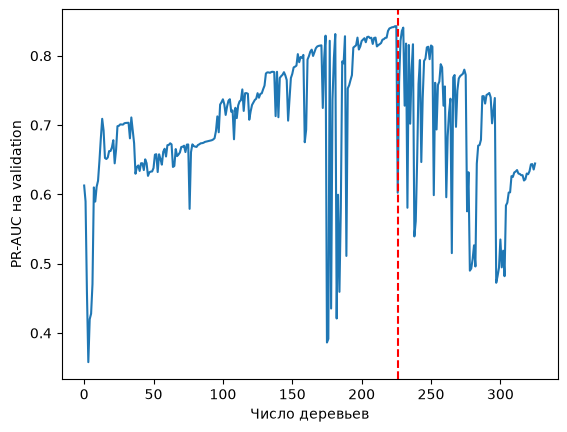

In [102]:
import matplotlib.pyplot as plt
curve = lgbm.evals_result_["valid_0"]["average_precision"]
plt.plot(curve)
plt.axvline(lgbm.best_iteration_, color="red", linestyle="--")
plt.xlabel("Число деревьев")
plt.ylabel("PR-AUC на validation")
plt.show()

In [103]:
imp = pd.Series(
    lgbm.booster_.feature_importance(importance_type="gain"),
    index=lgbm.booster_.feature_name()
).sort_values(ascending=False)
print((imp / imp.sum()).round(3))

log_old_balance_dest           0.721
log_amount_to_balance_ratio    0.130
log_amount                     0.058
transaction_type               0.053
log_old_balance_orig           0.026
hour_cos                       0.011
hour_sin                       0.000
destination_zero_balance       0.000
origin_zero_balance            0.000
dtype: float64


In [104]:
cont_no_ratio = [c for c in continuous_features if c != "log_amount_to_balance_ratio"]
cols_nr = cont_no_ratio + binary_features_prod + categorical_features

def prep(X_part, cols_):
    X_out = X_part[cols_].copy()
    X_out["transaction_type"] = X_out["transaction_type"].astype(
        pd.CategoricalDtype(categories=["CASH_OUT", "TRANSFER"])
    )
    return X_out

lgbm_nr = lgb.LGBMClassifier(
    n_estimators=2000, learning_rate=0.05, num_leaves=15,
    min_child_samples=200, scale_pos_weight=scale_pos_weight_sqrt,
    metric="None", random_state=42, n_jobs=-1, verbose=-1,
)
lgbm_nr.fit(
    prep(X_train, cols_nr), y_train,
    eval_set=[(prep(X_validation, cols_nr), y_validation)],
    eval_metric="average_precision",
    callbacks=[lgb.early_stopping(100), lgb.log_evaluation(50)],
)

from sklearn.metrics import average_precision_score
for part, Xp, yp in [("validation", X_validation, y_validation), ("test", X_test, y_test)]:
    p = lgbm_nr.predict_proba(prep(Xp, cols_nr))[:, 1]
    print(part, "PR-AUC без ratio:", round(average_precision_score(yp, p), 3))

c:\Users\Yerassyl\Desktop\fraud-detection\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


Training until validation scores don't improve for 100 rounds
[50]	valid_0's average_precision: 0.378165
[100]	valid_0's average_precision: 0.423129
Early stopping, best iteration is:
[3]	valid_0's average_precision: 0.486697
validation PR-AUC без ratio: 0.487
test PR-AUC без ratio: 0.583


In [105]:
thresholds = np.concatenate([
    np.arange(0.50, 0.99, 0.01),
    1 - np.logspace(-2, -6, 25)   # 0.99 ... 0.999999
])

In [106]:
t_gb = pick_threshold(lgbm, X_val_gb, y_validation)
print("Новый порог:", t_gb)

rows = []
for part, Xp, yp in [("validation", X_val_gb, y_validation),
                     ("test", X_test_gb, y_test)]:
    m = evaluate(lgbm, Xp, yp, t_gb)
    m.update(model="LightGBM", part=part, threshold=round(float(t_gb), 6))
    rows.append(m)

display(pd.DataFrame(rows)[["model", "part", "threshold", "precision",
                            "recall", "f1", "pr_auc", "TP", "FN", "FP"]].round(3))

Новый порог: 0.999999


,model,part,threshold,precision,recall,f1,pr_auc,TP,FN,FP
0,LightGBM,validation,1.0,0.738,0.802,0.769,0.739,449,111,159
1,LightGBM,test,1.0,0.937,0.823,0.876,0.924,3301,709,222


In [107]:
for name, mask in [("train", train_mask), ("validation", validation_mask), ("test", test_mask)]:
    d = model_df.loc[mask]
    fraud = d[d["is_fraud"] == 1]
    honest = d[d["is_fraud"] == 0]
    print(f"{name:11s} full_balance_attempt: среди мошенничества "
          f"{fraud['full_balance_attempt'].mean()*100:.1f}%, среди честных "
          f"{honest['full_balance_attempt'].mean()*100:.1f}%")

d = model_df.loc[test_mask]
rule = d["full_balance_attempt"]
print("Правило на test: precision",
      round(precision_score(d["is_fraud"], rule), 3),
      "recall", round(recall_score(d["is_fraud"], rule), 3))

train       full_balance_attempt: среди мошенничества 97.9%, среди честных 0.0%
validation  full_balance_attempt: среди мошенничества 99.1%, среди честных 0.0%
test        full_balance_attempt: среди мошенничества 97.2%, среди честных 0.0%
Правило на test: precision 1.0 recall 0.972


## LightGBM and the shortcut check

I trained LightGBM on the same features, without `day`, and got a PR-AUC of 0.905 on the test set (precision 0.91, recall 0.85). The logistic regression had 0.627. That jump looked too good, so I tried to find out where it came from.

Feature importance showed that almost everything rests on two features: `transaction_type` (0.59) and `log_amount_to_balance_ratio` (0.35). The ratio equals 1 when the whole balance is transferred, and a tree can pick out that exact value easily. So the simulator rule I had removed along with `full_balance_attempt` came back through a neighbouring feature. When I retrained without the ratio, test PR-AUC dropped to 0.58, below the logistic regression. That number is noisy, since early stopping halted at tree 3, so I treat it as a rough estimate.

Then I tested the simple rule "`full_balance_attempt == 1`" with no model at all:

| Approach | Test result |
|---|---|
| Rule: "whole balance transferred" | precision 1.00, recall 0.97 |
| LightGBM with ratio | PR-AUC 0.905, precision 0.91, recall 0.85 |
| Logistic regression without `day` | PR-AUC 0.627 |
| LightGBM without ratio | PR-AUC ~0.58 |

Among fraudulent transactions this flag is 1 in 97-99% of cases (in train, validation and test), and it never appears among legitimate ones. A single line of code beats the boosted model.

**Conclusion.** In PaySim, fraud is defined by the generator's own rule. A model that sees this signal just repeats it and adds nothing on top, and without it the model performs much worse. So 0.905 should not be read as the quality of a model on real fraud. Next I want to see what can be found when the rule is not available, for example by using the transaction history of the recipient account.

In [108]:
risk_df.columns.tolist()

['step',
 'transaction_type',
 'amount',
 'old_balance_orig',
 'new_balance_orig',
 'old_balance_dest',
 'new_balance_dest',
 'is_fraud',
 'name_orig',
 'name_dest',
 'is_flagged_fraud']

In [110]:
orig_col = "name_orig"   # подставь своё название
dest_col = "name_dest"   # подставь своё название

print("Отправителей:", risk_df[orig_col].nunique(), "из", len(risk_df))
print("Получателей: ", risk_df[dest_col].nunique(), "из", len(risk_df))

cnt = risk_df[dest_col].map(risk_df[dest_col].value_counts())
print("Среднее число операций на счёт получателя:")
print("  мошенничество:", round(cnt[risk_df["is_fraud"] == 1].mean(), 2))
print("  честные:      ", round(cnt[risk_df["is_fraud"] == 0].mean(), 2))

Отправителей: 2768630 из 2770409
Получателей:  509565 из 2770409
Среднее число операций на счёт получателя:
  мошенничество: 5.7
  честные:       11.6


In [111]:
tmp = risk_df[[dest_col, "step"]].copy()

# сколько операций на счёт получателя в каждый час
per_hour = (
    tmp.groupby([dest_col, "step"]).size().rename("n_in_step").reset_index()
    .sort_values([dest_col, "step"])
)

# накопленная сумма минус текущий час = число операций строго до этого часа
per_hour["dest_prev_ops"] = (
    per_hour.groupby(dest_col)["n_in_step"].cumsum() - per_hour["n_in_step"]
)

tmp = tmp.merge(per_hour[[dest_col, "step", "dest_prev_ops"]],
                on=[dest_col, "step"], how="left")

model_df["dest_prev_ops"] = tmp["dest_prev_ops"].to_numpy()
model_df["log_dest_prev_ops"] = np.log1p(model_df["dest_prev_ops"]).astype("float32")

print(model_df.groupby("is_fraud")["dest_prev_ops"].describe())

              count      mean       std  min  25%  50%  75%   max
is_fraud                                                         
0         2762196.0  5.226312  6.007384  0.0  1.0  3.0  8.0  74.0
1            8213.0  1.763424  4.120821  0.0  0.0  0.0  1.0  46.0


In [112]:
model_df["period"] = pd.cut(model_df["step"], bins=[0, 200, 400, 600, 743])
print(
    model_df.groupby(["period", "is_fraud"], observed=True)["dest_prev_ops"]
    .agg(["count", "mean", "median"])
)

# доля операций с «новым» получателем
new_dest = (model_df["dest_prev_ops"] == 0)
print(new_dest.groupby(model_df["is_fraud"]).mean().round(3))

                       count      mean  median
period     is_fraud                           
(0, 200]   0         1043074  4.908120     3.0
           1            2254  1.667258     0.0
(200, 400] 0         1481985  5.432440     3.0
           1            2223  1.739541     0.0
(400, 600] 0          195187  5.393868     3.0
           1            2136  1.829588     0.0
(600, 743] 0           41950  5.076472     3.0
           1            1600  1.843750     0.0
is_fraud
0    0.194
1    0.673
Name: dest_prev_ops, dtype: float64


In [113]:
model_df["dest_is_new"] = (model_df["dest_prev_ops"] == 0).astype("int8")
# log_dest_prev_ops у тебя уже есть

base_cont = [c for c in continuous_features if c != "log_amount_to_balance_ratio"]
configs = {
    "без ratio, без истории": (base_cont, binary_features_prod),
    "без ratio, с историей": (base_cont + ["log_dest_prev_ops"],
                              binary_features_prod + ["dest_is_new"]),
}

def prep2(X_part, cols_):
    out = X_part[cols_].copy()
    out["transaction_type"] = out["transaction_type"].astype(
        pd.CategoricalDtype(categories=["CASH_OUT", "TRANSFER"])
    )
    return out

# новые столбцы надо подтянуть в X_train/X_validation/X_test
extra = ["log_dest_prev_ops", "dest_is_new"]
Xtr = pd.concat([X_train, model_df.loc[train_mask, extra]], axis=1)
Xva = pd.concat([X_validation, model_df.loc[validation_mask, extra]], axis=1)
Xte = pd.concat([X_test, model_df.loc[test_mask, extra]], axis=1)

rows = []
for name, (cont, binf) in configs.items():
    cols_ = cont + binf + categorical_features
    m = lgb.LGBMClassifier(
        n_estimators=2000, learning_rate=0.05, num_leaves=15,
        min_child_samples=200, scale_pos_weight=scale_pos_weight_sqrt,
        metric="None", random_state=42, n_jobs=-1, verbose=-1,
    )
    m.fit(prep2(Xtr, cols_), y_train,
          eval_set=[(prep2(Xva, cols_), y_validation)],
          eval_metric="average_precision",
          callbacks=[lgb.early_stopping(100)])
    rows.append({
        "модель": name,
        "деревьев": m.best_iteration_,
        "PR-AUC val": average_precision_score(y_validation, m.predict_proba(prep2(Xva, cols_))[:, 1]),
        "PR-AUC test": average_precision_score(y_test, m.predict_proba(prep2(Xte, cols_))[:, 1]),
    })

display(pd.DataFrame(rows).round(3))

c:\Users\Yerassyl\Desktop\fraud-detection\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


Training until validation scores don't improve for 100 rounds
Early stopping, best iteration is:
[3]	valid_0's average_precision: 0.486697


c:\Users\Yerassyl\Desktop\fraud-detection\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


Training until validation scores don't improve for 100 rounds
Early stopping, best iteration is:
[3]	valid_0's average_precision: 0.478863


,модель,деревьев,PR-AUC val,PR-AUC test
0,"без ratio, без истории",3,0.487,0.583
1,"без ratio, с историей",3,0.479,0.578


In [115]:
res.keys()

dict_keys(['valid_0', 'valid_1'])

c:\Users\Yerassyl\Desktop\fraud-detection\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


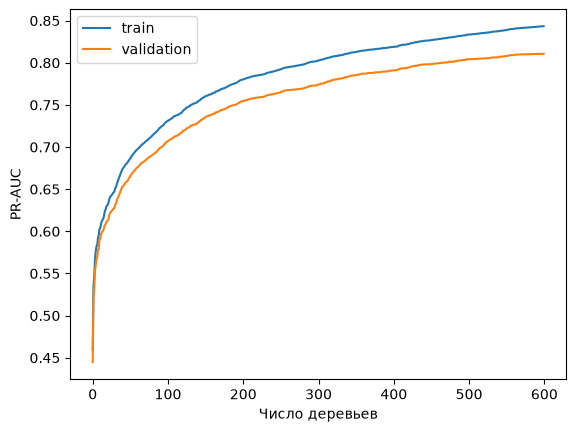

In [116]:

cols_ = base_cont + ["log_dest_prev_ops"] + binary_features_prod + ["dest_is_new"] + categorical_features

m = lgb.LGBMClassifier(
    n_estimators=600, learning_rate=0.02, num_leaves=15,
    min_child_samples=500, scale_pos_weight=1,
    metric="None", random_state=42, n_jobs=-1, verbose=-1,
)
m.fit(
    prep2(Xtr, cols_), y_train,
    eval_set=[(prep2(Xtr, cols_), y_train), (prep2(Xva, cols_), y_validation)],
    eval_metric="average_precision",
)

res = m.evals_result_
plt.plot(res["valid_0"]["average_precision"], label="train")
plt.plot(res["valid_1"]["average_precision"], label="validation")
plt.xlabel("Число деревьев")
plt.ylabel("PR-AUC")
plt.legend()
plt.show()

In [117]:

configs = {
    "без ratio, без истории": (base_cont, binary_features_prod),
    "без ratio, с историей": (base_cont + ["log_dest_prev_ops"],
                              binary_features_prod + ["dest_is_new"]),
}

rows, models_hard = [], {}
for name, (cont, binf) in configs.items():
    cols_ = cont + binf + categorical_features
    m = lgb.LGBMClassifier(
        n_estimators=600, learning_rate=0.02, num_leaves=15,
        min_child_samples=500, scale_pos_weight=1,
        metric="None", random_state=42, n_jobs=-1, verbose=-1,
    )
    m.fit(prep2(Xtr, cols_), y_train)
    models_hard[name] = (m, cols_)

    rows.append({
        "модель": name,
        "PR-AUC val": average_precision_score(y_validation, m.predict_proba(prep2(Xva, cols_))[:, 1]),
        "PR-AUC test": average_precision_score(y_test, m.predict_proba(prep2(Xte, cols_))[:, 1]),
    })

display(pd.DataFrame(rows).round(3))

# важность признаков модели с историей
m, cols_ = models_hard["без ratio, с историей"]
imp = pd.Series(m.booster_.feature_importance(importance_type="gain"),
                index=m.booster_.feature_name()).sort_values(ascending=False)
print((imp / imp.sum()).round(3))

,модель,PR-AUC val,PR-AUC test
0,"без ratio, без истории",0.812,0.914
1,"без ratio, с историей",0.811,0.911


log_amount                  0.468
log_old_balance_orig        0.275
hour_cos                    0.082
log_old_balance_dest        0.062
transaction_type            0.055
hour_sin                    0.036
destination_zero_balance    0.014
log_dest_prev_ops           0.007
dest_is_new                 0.001
origin_zero_balance         0.000
dtype: float64


In [118]:
all_cont = base_cont + ["log_dest_prev_ops"]
all_bin = binary_features_prod + ["dest_is_new"]

def drop(cont, binf, remove):
    return ([c for c in cont if c not in remove],
            [c for c in binf if c not in remove])

experiments = {
    "все признаки":                 drop(all_cont, all_bin, []),
    "без log_old_balance_orig":     drop(all_cont, all_bin, ["log_old_balance_orig"]),
    "без log_amount":               drop(all_cont, all_bin, ["log_amount"]),
    "без обоих":                    drop(all_cont, all_bin, ["log_old_balance_orig", "log_amount"]),
}

rows = []
for name, (cont, binf) in experiments.items():
    cols_ = cont + binf + categorical_features
    m = lgb.LGBMClassifier(
        n_estimators=600, learning_rate=0.02, num_leaves=15,
        min_child_samples=500, scale_pos_weight=1,
        metric="None", random_state=42, n_jobs=-1, verbose=-1,
    )
    m.fit(prep2(Xtr, cols_), y_train)
    rows.append({
        "эксперимент": name,
        "PR-AUC val": average_precision_score(y_validation, m.predict_proba(prep2(Xva, cols_))[:, 1]),
        "PR-AUC test": average_precision_score(y_test, m.predict_proba(prep2(Xte, cols_))[:, 1]),
    })

display(pd.DataFrame(rows).round(3))

,эксперимент,PR-AUC val,PR-AUC test
0,все признаки,0.811,0.911
1,без log_old_balance_orig,0.412,0.653
2,без log_amount,0.520,0.710
3,без обоих,0.322,0.430


In [119]:
rule_test = Xte["full_balance_attempt"] if "full_balance_attempt" in Xte else \
            model_df.loc[test_mask, "full_balance_attempt"]
m, cols_ = models_hard["без ratio, с историей"]
proba = m.predict_proba(prep2(Xte, cols_))[:, 1]

missed = (y_test == 1) & (rule_test == 0)
print("Мошенничества, которые правило пропускает:", int(missed.sum()), "из", int(y_test.sum()))

# насколько модель ранжирует их выше честных операций (где правило тоже не сработало)
subset = (rule_test == 0)
print("PR-AUC на операциях без срабатывания правила:",
      round(average_precision_score(y_test[subset], proba[subset]), 3))

print(model_df.loc[test_mask][missed.values][
    ["transaction_type", "amount", "old_balance_orig", "new_balance_orig",
     "old_balance_dest", "dest_prev_ops"]
].describe().round(1))

Мошенничества, которые правило пропускает: 114 из 4010
PR-AUC на операциях без срабатывания правила: 0.952
           amount  old_balance_orig  new_balance_orig  old_balance_dest  \
count       114.0             114.0             114.0             114.0   
mean    8748248.6        18943478.5        10610145.1          122277.8   
std     3287046.9        12684925.1        11311890.9          805341.6   
min           0.0               0.0               0.0               0.0   
25%    10000000.0        12120176.1         2202021.7               0.0   
50%    10000000.0        15955790.4         6359677.7               0.0   
75%    10000000.0        24192996.8        15660455.9               0.0   
max    10000000.0        59585040.4        49585040.4         7970766.6   

       dest_prev_ops  
count          114.0  
mean             0.4  
std              2.1  
min              0.0  
25%              0.0  
50%              0.0  
75%              0.0  
max             17.0  


In [120]:
d = model_df.loc[test_mask]
cap = (d["amount"] == 10_000_000)

print("Операций с суммой ровно 10 млн:", int(cap.sum()))
print("Доля мошенничества среди них:", round(d.loc[cap, "is_fraud"].mean(), 3))
print("Мошенничества с суммой 10 млн:", int((cap & (d["is_fraud"] == 1)).sum()), "из", int(d["is_fraud"].sum()))

rule2 = ((d["full_balance_attempt"] == 1) | cap).astype(int)
print("Правило v2: precision", round(precision_score(d["is_fraud"], rule2), 3),
      "recall", round(recall_score(d["is_fraud"], rule2), 3))

Операций с суммой ровно 10 млн: 213
Доля мошенничества среди них: 0.906
Мошенничества с суммой 10 млн: 193 из 4010
Правило v2: precision 0.995 recall 0.996


## What the model actually learned

LightGBM reached a test PR-AUC of about 0.91, which looked great until I started checking where it came from. Here is the chain of checks.

| Approach | Test result |
|---|---|
| Rule: whole balance transferred | precision 1.00, recall 0.97 |
| Rule v2: whole balance transferred OR amount is exactly 10,000,000 | precision 0.995, recall 0.996 |
| Logistic regression (no `day`) | PR-AUC 0.627 |
| LightGBM, all features | PR-AUC 0.911 |
| LightGBM without `log_old_balance_orig` | PR-AUC 0.653 |
| LightGBM without `log_amount` | PR-AUC 0.710 |
| LightGBM without both | PR-AUC 0.430 |

Removing `full_balance_attempt` and the ratio did not help: the model rebuilt the same rule from the amount and the sender's balance. Only when both of those are removed does the score drop (0.43). The rule itself misses only 114 of 4,010 frauds in the test set. Almost all of them have an amount of exactly 10,000,000, so it looks like the simulator caps a single transaction at 10 million. When the balance is larger than the cap, the fraudster moves the cap amount instead of the whole balance. Adding this second condition brings recall to 0.996.

I also tried history features for the recipient account (number of earlier operations, "new recipient" flag). They differ a lot between classes: 67% of frauds go to a recipient with no history against 19% of legitimate operations, and this holds in every time period. But on top of the amount and balance they add nothing (0.911 vs 0.914).

**Conclusion.** In PaySim, fraud is generated by a simple rule, and any model that sees the amount and the sender's balance will find it. A high PR-AUC here measures how well the rule was learned, not how well real fraud would be caught. The score without those features (0.43) is only a lower bound, because removing them also removes other useful information.

In [121]:
import joblib
from pathlib import Path

final_cont = base_cont                       # без log_amount_to_balance_ratio, без истории
final_bin = binary_features_prod
final_cols = final_cont + final_bin + categorical_features

final_model = lgb.LGBMClassifier(
    n_estimators=600, learning_rate=0.02, num_leaves=15,
    min_child_samples=500, scale_pos_weight=1,
    metric="None", random_state=42, n_jobs=-1, verbose=-1,
)
final_model.fit(prep2(Xtr, final_cols), y_train)

p_val = final_model.predict_proba(prep2(Xva, final_cols))[:, 1]
p_test = final_model.predict_proba(prep2(Xte, final_cols))[:, 1]
print("PR-AUC val:", round(average_precision_score(y_validation, p_val), 3))
print("PR-AUC test:", round(average_precision_score(y_test, p_test), 3))

# --- бюджет проверок: берём k самых рискованных операций на test ---
order = np.argsort(-p_test)
y_sorted = y_test.to_numpy()[order]
total_fraud = int(y_test.sum())

rows = []
for k in [500, 1000, 2000, 3000, 4000, 5000, 8000]:
    tp = int(y_sorted[:k].sum())
    rows.append({"k (проверок)": k, "поймано": tp,
                 "precision@k": round(tp / k, 3),
                 "recall@k": round(tp / total_fraud, 3)})
display(pd.DataFrame(rows))

# --- сохранение ---
Path("../models").mkdir(exist_ok=True)
joblib.dump({"model": final_model, "columns": final_cols}, "../models/lgbm_fraud.joblib")

PR-AUC val: 0.812
PR-AUC test: 0.914


,k (проверок),поймано,precision@k,recall@k
0,500,500,1.000,0.125
1,1000,1000,1.000,0.249
2,2000,1994,0.997,0.497
3,3000,2868,0.956,0.715
4,4000,3385,0.846,0.844
5,5000,3539,0.708,0.883
6,8000,3773,0.472,0.941


['../models/lgbm_fraud.joblib']